# MRax: Getting Started

Build a minimal synthetic study with T1 inversion-recovery and T2 spin-echo experiments, fit the provided models, visualize the results, and save the study outputs. All inputs are generated inside the notebook.


**Parameter defaults:** Bounds, transforms, and initial values for built-in models live in `mrax/library/parameter_library.toml`.
Use `param_key` to pick a preset and `param_overrides` to tweak specific parameters when calling `make_*_model`.


In [1]:
from pathlib import Path
import math

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np


from mrax.core.loss_builder import run_fit
from mrax.core.study_runner import execute_study_plan, plan_study_fits
from mrax.data_struct import DataSet, Experiment, Model, Quantity, Study, save_study_results, load_study_results
from mrax.library import make_t1_ir_model, make_t2_se_model


def apply_publication_style():
    plt.rcParams.update({
        "figure.dpi": 110,
        "savefig.dpi": 300,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "font.size": 10,
    })


def _as_array(value):
    return np.asarray(value.values if isinstance(value, Quantity) else value)


def _prepare_map(value):
    arr = np.asarray(value)
    if arr.ndim == 0:
        return arr.reshape(1, 1)
    if arr.ndim == 1:
        return arr[:, None]
    if arr.ndim > 2:
        arr = np.mean(arr, axis=tuple(range(2, arr.ndim)))
    return arr


def _limits(arr):
    vmin, vmax = np.nanpercentile(arr, [2, 98])
    return (None, None) if np.isclose(vmin, vmax) else (float(vmin), float(vmax))


def plot_parameter_maps(fields, units=None):
    keys = list(fields)
    ncols = min(3, len(keys))
    nrows = math.ceil(len(keys) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.3 * nrows))
    axes = np.atleast_1d(axes).reshape(nrows, ncols)
    for ax, key in zip(axes.flat, keys):
        arr = _prepare_map(_as_array(fields[key]))
        vmin, vmax = _limits(arr)
        im = ax.imshow(arr, cmap="viridis", vmin=vmin, vmax=vmax)
        unit = fields[key].si_unit if isinstance(fields[key], Quantity) else (units or {}).get(key, "")
        ax.set_title(f"{key.replace('_', ' ').title()}" + (f" [{unit}]" if unit else ""))
        ax.set_xticks([])
        ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    for ax in axes.flat[len(keys):]:
        ax.axis("off")
    fig.tight_layout()
    return fig


def plot_loss_history(loss_history):
    losses = np.asarray(loss_history)
    if losses.size == 0:
        return None
    fig, ax = plt.subplots(figsize=(4.6, 3.2))
    ax.plot(np.arange(losses.size), losses.reshape(-1), linewidth=2)
    ax.set_xlabel("Optimization step")
    ax.set_ylabel("Loss")
    ax.set_title("Fit convergence")
    ax.grid(True, linestyle=":", alpha=0.6)
    fig.tight_layout()
    return fig


def plot_image_overview(image, title="MR magnitude"):
    arr = _prepare_map(np.abs(image))
    vmin, vmax = _limits(arr)
    fig, ax = plt.subplots(figsize=(4, 4))
    im = ax.imshow(arr, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="a.u.")
    fig.tight_layout()
    return fig


def plot_voxel_spectra(offsets, observed, predicted=None, sample_points=None):
    offsets = np.asarray(offsets).reshape(-1)
    obs = np.asarray(observed)
    pred = None if predicted is None else np.asarray(predicted)
    if obs.shape[-1] != offsets.size and obs.shape[0] == offsets.size:
        obs = np.moveaxis(obs, 0, -1)
    if pred is not None and pred.shape[-1] != offsets.size and pred.shape[0] == offsets.size:
        pred = np.moveaxis(pred, 0, -1)
    if sample_points is None:
        sample_points = [(obs.shape[0] // 2, obs.shape[1] // 2)]
    fig, axes = plt.subplots(1, len(sample_points), figsize=(4 * len(sample_points), 3.2), squeeze=False)
    for ax, (i, j) in zip(axes.flat, sample_points):
        ax.plot(offsets, obs[i, j].reshape(-1), "o-", label="Measured", markersize=3)
        if pred is not None:
            ax.plot(offsets, pred[i, j].reshape(-1), "--", linewidth=2, label="Model fit")
        ax.set_title(f"Voxel x={i}, y={j}")
        ax.set_xlabel("Observable")
        ax.set_ylabel("Signal")
        ax.legend()
        ax.grid(True, linestyle=":", alpha=0.6)
    fig.tight_layout()
    return fig


plt.rcParams["figure.figsize"] = (6, 4)
apply_publication_style()


## Build a tiny synthetic T1/T2 study

We'll create two small experiments with observables (`TI` for T1 inversion recovery and `TE` for T2 spin-echo), wrap the built-in models so the offset axis is last `(x, y, time)`, and generate noisy synthetic data.


In [2]:
from mrax.core.loss_builder import make_model_callable


def make_truth_maps(nx: int = 16, ny: int = 16):
    xg, yg = jnp.meshgrid(jnp.linspace(0.0, 1.0, nx), jnp.linspace(0.0, 1.0, ny), indexing="ij")
    amp = 0.9 + 0.25 * jnp.sin(2.0 * jnp.pi * xg) * jnp.cos(2.0 * jnp.pi * yg)
    t1_map = 1500.0 + 500.0 * jnp.sin(jnp.pi * xg) * jnp.cos(jnp.pi * yg)
    t2_map = 50.0 + 25.0 * jnp.cos(jnp.pi * yg)
    bias_map = 0.05 * jnp.cos(2.0 * jnp.pi * (xg + yg))
    return {
        "t1_ir": {"amplitude": amp, "t1": t1_map},
        "t2_se": {"amplitude": 0.85 * amp + 0.15, "t2": t2_map, "bias": bias_map},
    }


def simulate_experiment(
    name: str,
    model: Model,
    fields: dict,
    offsets: jnp.ndarray,
    offset_key: str,
    unit: str,
    noise_level: float,
    rng,
):
    spatial = np.asarray(next(iter(fields.values()))).shape
    if len(spatial) < 2:
        raise ValueError("Expected 2D spatial fields for synthetic experiment.")
    nx, ny = spatial[-2], spatial[-1]
    experiment = Experiment(
        dims={"x": nx, "y": ny, "time": int(offsets.shape[0])},
        observables={offset_key: Quantity(offsets, unit)},
        exp_type=name,
    )
    model_callable = make_model_callable(experiment, model)
    clean = model_callable(fields, offsets)
    if clean.ndim == 3 and clean.shape[0] == offsets.shape[0]:
        clean = jnp.moveaxis(clean, 0, -1)
    noise = noise_level * jax.random.normal(rng, clean.shape)
    data = clean + noise
    dataset = DataSet(data=jnp.asarray(data), name=name, noise_level=noise_level)
    return dataset, experiment, clean


def build_synthetic_study(noise_level: float = 0.03, seed: int = 0):
    rng = jax.random.PRNGKey(seed)
    ti_ms = jnp.linspace(80.0, 6000.0, 10)
    te_ms = jnp.linspace(8.0, 200.0, 12)

    truth = make_truth_maps()
    t1_model = make_t1_ir_model()
    t2_model = make_t2_se_model()

    rng, k1, k2 = jax.random.split(rng, 3)
    t1_ds, t1_exp, t1_clean = simulate_experiment(
        "t1_ir", t1_model, truth["t1_ir"], ti_ms, "TI", "ms", noise_level, k1
    )
    t2_ds, t2_exp, t2_clean = simulate_experiment(
        "t2_se", t2_model, truth["t2_se"], te_ms, "TE", "ms", noise_level, k2
    )

    study_globals = {"field_strength_mhz": Quantity(400.0, "MHz")}
    study = Study(
        experiments=[t1_exp, t2_exp],
        datasets=[t1_ds, t2_ds],
        models=[t1_model, t2_model],
        names=["t1_ir", "t2_se"],
        study_globals=study_globals,
    )

    extras = {
        "offsets": {"t1_ir": ti_ms, "t2_se": te_ms},
        "clean": {"t1_ir": t1_clean, "t2_se": t2_clean},
    }
    return study, truth, extras


Create the study and peek at the synthetic inputs.

Experiments: ['t1_ir', 't2_se']
  t1_ir: data shape (16, 16, 10), observables [TI]
  t2_se: data shape (16, 16, 12), observables [TE]


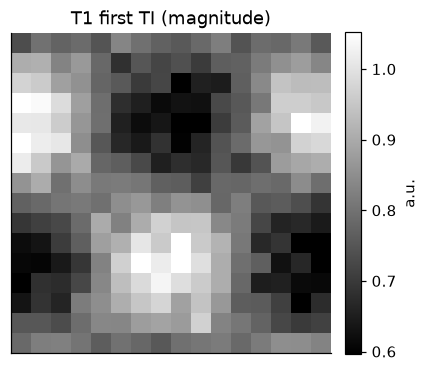

In [3]:

study, truth_fields, synthetic = build_synthetic_study(noise_level=0.03, seed=0)
print("Experiments:", study.names)
for name, exp, ds in zip(study.names, study.experiments, study.datasets):
    obs = ", ".join(exp.observables.keys())
    print(f"  {name}: data shape {ds.shape}, observables [{obs}]")

_ = plot_image_overview(np.abs(study.datasets[0].data[..., 0]), title="T1 first TI (magnitude)")


## Fit both experiments

Use `plan_study_fits`/`execute_study_plan` to run the two fits back-to-back. Shared fit options go in `run_fit_kwargs`; per-experiment overrides can be passed with `run_fit_overrides` or, for scalar options, dictionaries keyed by experiment name.


In [4]:

plan = plan_study_fits(study)
results, fitted_fields = execute_study_plan(
    plan,
    run_fit_kwargs={
        "num_steps": {"t1_ir": 150, "t2_se": 150},
        "step_size": 0.03,
    },
)
results_by_name = {r["name"]: r for r in results}
for name in study.names:
    losses = results_by_name[name]["loss_history"]
    print(f"{name}: initial loss {losses[0]:.4f} -> final loss {losses[-1]:.4f}")


t1_ir: initial loss 0.2296 -> final loss 0.0017
t2_se: initial loss 0.2111 -> final loss 0.0074


## Visualize fitted maps and spectra

Plot parameter maps, voxel spectra, and loss history for each experiment.


(<Figure size 880x363 with 4 Axes>,
 <Figure size 440x352 with 1 Axes>,
 <Figure size 506x352 with 1 Axes>)

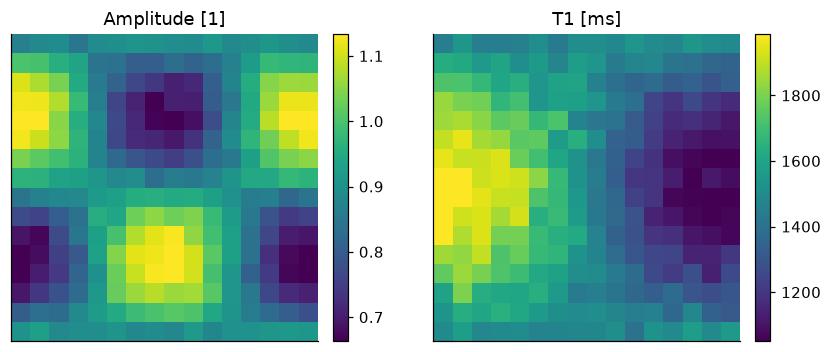

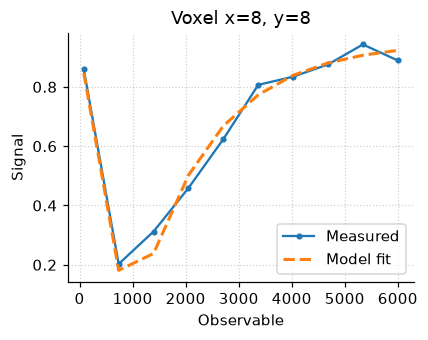

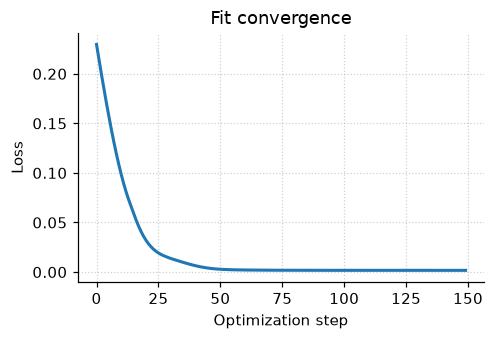

In [5]:
from mrax.core.loss_builder import make_model_callable


def _unwrap_fields(fields: dict):
    return {k: (v.values if isinstance(v, Quantity) else v) for k, v in fields.items()}


def visualize_result(name: str):
    idx = study.names.index(name)
    exp = study.experiments[idx]
    model = study.models[idx]
    offsets = next(iter(exp.observables.values())).values
    observed = np.asarray(study.datasets[idx].data)
    field_map = fitted_fields[name]

    model_callable = make_model_callable(exp, model, study_globals=getattr(exp, "study_globals", None))
    predicted = model_callable(_unwrap_fields(field_map), offsets)
    if predicted.ndim == 3 and observed.ndim == 3 and predicted.shape[0] == observed.shape[-1]:
        predicted = np.moveaxis(predicted, 0, -1)

    maps_fig = plot_parameter_maps(field_map, units=model.parameter_units)
    spectra_fig = plot_voxel_spectra(offsets, observed, predicted)
    loss_fig = plot_loss_history(results_by_name[name]["loss_history"])
    return maps_fig, spectra_fig, loss_fig


visualize_result("t1_ir")


(<Figure size 1320x363 with 6 Axes>,
 <Figure size 440x352 with 1 Axes>,
 <Figure size 506x352 with 1 Axes>)

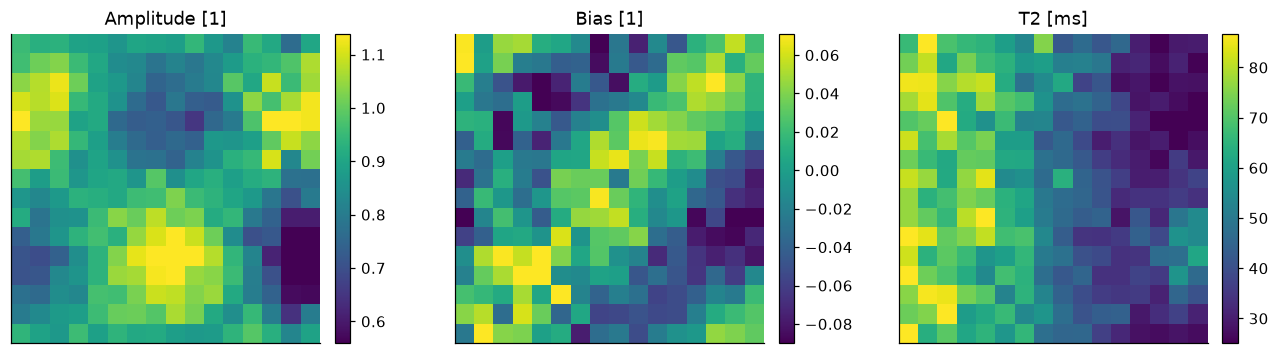

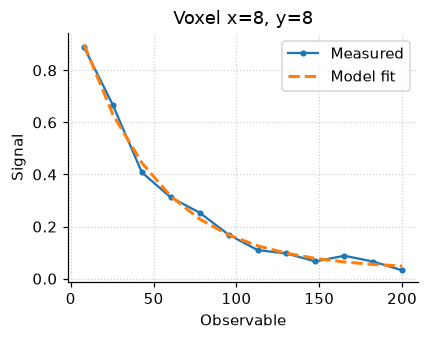

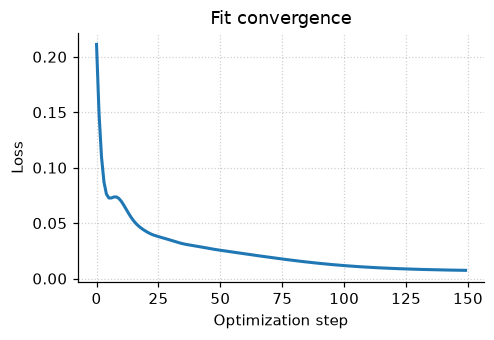

In [6]:

visualize_result("t2_se")


## Save and reload the study

Persist fitted fields to disk with `save_study_results`, then reload the manifest. Plotting stays notebook-local in the cells above.


In [7]:

out_dir = Path.cwd() / "tmp" / "getting_started_demo"
manifest = save_study_results(study, results, out_dir, study_name="t1_t2_demo")
print("Manifest written to", manifest)

loaded = load_study_results(manifest)
first = study.names[0]
print("Reloaded fitted maps for", first, ":", sorted(loaded["experiments"][first]["fitted_maps"].keys()))


Manifest written to tmp/getting_started_demo/study_manifest.json
Reloaded fitted maps for t1_ir : ['amplitude', 't1']
